<a href="https://colab.research.google.com/github/Sreejithjayachandran/Assessment_Supervised_Learning_SreejithJ/blob/main/Assessment_Supervised_Learning_SreejithJ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [116]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Data understanding and exploratory analysis **bold text**

In [19]:
# Reading the data from the drive
df=pd.read_csv('/content/drive/MyDrive/DSA/Assessment/Assessment_Supervise_Learning/bank_marketing_assessment_dataset.csv')
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [3]:
# Checking the shape of the dataset
df.shape

(600, 14)

In [5]:
# Inspecting the column names
print(df.columns)

Index(['customer_age', 'job', 'marital_status', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact_type', 'contact_month',
       'campaign_contacts', 'previous_contacts', 'engagement_score',
       'annual_income_estimate', 'subscribed'],
      dtype='object')


In [7]:
# Checking the datatypes
print(df.dtypes)

customer_age                int64
job                        object
marital_status             object
education                  object
account_balance           float64
housing_loan               object
personal_loan              object
contact_type               object
contact_month              object
campaign_contacts           int64
previous_contacts           int64
engagement_score            int64
annual_income_estimate      int64
subscribed                 object
dtype: object


In [10]:
# Checking and calculating more details about the data set
print(df.describe())

       customer_age  account_balance  campaign_contacts  previous_contacts  \
count    600.000000       588.000000         600.000000         600.000000   
mean      38.208333      1535.037415           5.566667           1.015000   
std       15.387426      2366.916896           2.020485           1.582914   
min       18.000000     -5418.000000           3.000000           0.000000   
25%       26.000000       -24.750000           4.000000           0.000000   
50%       34.000000      1589.500000           5.000000           0.000000   
75%       49.000000      3042.750000           7.000000           2.000000   
max       75.000000      9365.000000          13.000000           8.000000   

       engagement_score  annual_income_estimate  
count        600.000000                600.0000  
mean           4.451667              31805.3650  
std            2.938603              17264.0821  
min            1.000000              12000.0000  
25%            1.000000              16112.5000

In [11]:
#Checking the presence of null values in the data set and finding the count of the same
print(df.isnull().sum())

customer_age               0
job                        0
marital_status             0
education                 15
account_balance           12
housing_loan               0
personal_loan              0
contact_type               9
contact_month              0
campaign_contacts          0
previous_contacts          0
engagement_score           0
annual_income_estimate     0
subscribed                 0
dtype: int64


In [21]:
# Checking the duplicatyes in the datraset
print(df.duplicated().sum())

0


In [22]:
# Correlation of dataset
print(df.corr(numeric_only=True))

                        customer_age  account_balance  campaign_contacts  \
customer_age                1.000000        -0.057309           0.262320   
account_balance            -0.057309         1.000000           0.001141   
campaign_contacts           0.262320         0.001141           1.000000   
previous_contacts           0.004532         0.028662           0.238496   
engagement_score            0.078697         0.061718          -0.069610   
annual_income_estimate      0.075458        -0.021493           0.034936   

                        previous_contacts  engagement_score  \
customer_age                     0.004532          0.078697   
account_balance                  0.028662          0.061718   
campaign_contacts                0.238496         -0.069610   
previous_contacts                1.000000          0.306119   
engagement_score                 0.306119          1.000000   
annual_income_estimate           0.170835          0.290735   

                        a

In [23]:
#printing info
print(df.info)

<bound method DataFrame.info of      customer_age          job marital_status  education  account_balance  \
0              69      retired       divorced  secondary           5467.0   
1              21        admin         single  secondary            606.0   
2              27   technician        married   tertiary           -314.0   
3              53   management         single  secondary           1503.0   
4              51   management         single  secondary           3037.0   
..            ...          ...            ...        ...              ...   
595            30  blue-collar         single    primary            638.0   
596            68  blue-collar         single   tertiary            -70.0   
597            33        admin         single  secondary              7.0   
598            28        admin         single  secondary           1831.0   
599            50        admin         single  secondary           2345.0   

    housing_loan personal_loan contact_type

In [85]:
print(df.nunique())

customer_age               57
job                         6
marital_status              3
education                   3
account_balance           570
housing_loan                2
personal_loan               2
contact_type                3
contact_month               6
campaign_contacts          11
previous_contacts           9
engagement_score           10
annual_income_estimate    481
subscribed                  2
dtype: int64


In [87]:
#Checking the data count in taget colum
print(df['subscribed'].value_counts())


subscribed
no     426
yes    174
Name: count, dtype: int64


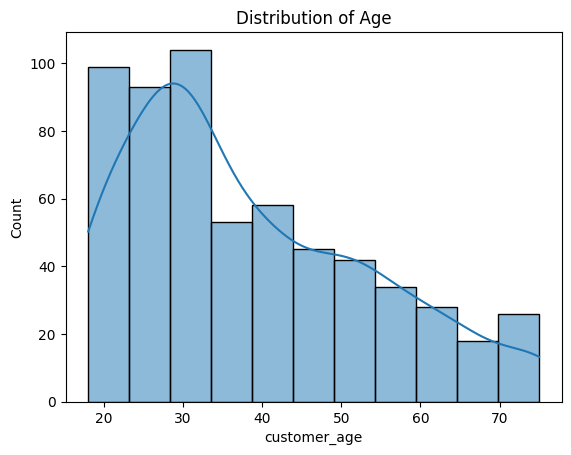

In [89]:
plt.title('Distribution of Age')
sns.histplot(df['customer_age'], kde=True)
plt.show()

### 1.3: Target Class Distribution


****  I choose 'SUBSCRIBED' as the target column  ****


Target Class Counts:
subscribed
no     426
yes    174
Name: count, dtype: int64

Target Class Percentages:
subscribed
no     71.0
yes    29.0
Name: proportion, dtype: float64


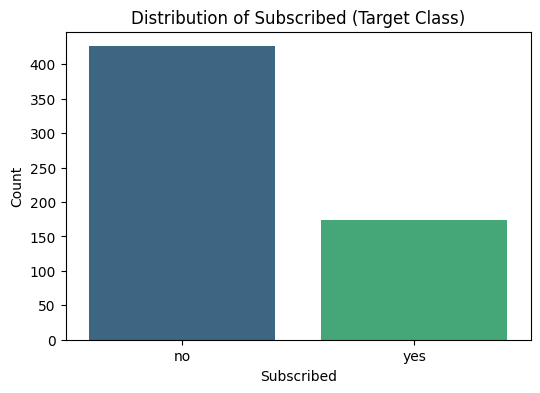

In [92]:
#Choosing the taget column
print("****  I choose 'SUBSCRIBED' as the target column  ****")
print("\n")
# Calculate counts and percentages
target_counts = df['subscribed'].value_counts()
target_pct = df['subscribed'].value_counts(normalize=True) * 100
print("Target Class Counts:")

print(target_counts)
print("\nTarget Class Percentages:")
print(target_pct.round(2))

# Plot distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='subscribed', hue='subscribed', palette='viridis', legend=False)
plt.title('Distribution of Subscribed (Target Class)')
plt.xlabel('Subscribed')
plt.ylabel('Count')
plt.show()

### 1.3.2: Observation 1: Engagement Score vs. Subscription status


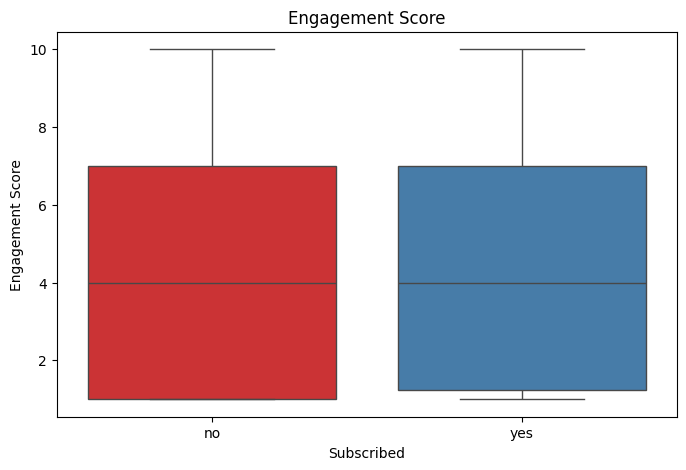

In [62]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='subscribed', y='engagement_score', hue='subscribed', palette='Set1', legend=False)
plt.title('Engagement Score')
plt.xlabel('Subscribed')
plt.ylabel('Engagement Score')
plt.show()

### 1.3.3: Observation 2: Campaign Contacts vs. Subscription status


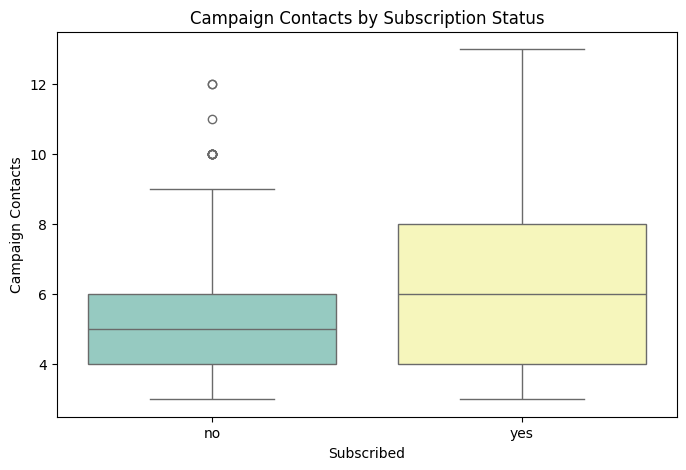

In [117]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='subscribed', y='campaign_contacts', hue='subscribed', palette='Set3', legend=False)
plt.title('Campaign Contacts by Subscription Status')
plt.xlabel('Subscribed')
plt.ylabel('Campaign Contacts')
plt.show()

## 2. Data Preparation and Feature Engineering



In [108]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Separate input features (X) and target (y)
X = df.drop(columns=['subscribed'])
y = df['subscribed'].map({'yes': 1, 'no': 0})

# 2. Split data into training and test sets (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (480, 13)
Test set shape: (120, 13)


In [109]:
df['account_balance'] = df['account_balance'].fillna(
    df['account_balance'].median())

df.isna().sum()

,0
customer_age,0
job,0
marital_status,0
education,0
account_balance,0
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [110]:
education_mode = df['education'].mode()[0]
df['education'] = df['education'].fillna(education_mode)

df.isna().sum()

,0
customer_age,0
job,0
marital_status,0
education,0
account_balance,0
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [112]:
print(df.isnull().sum())

customer_age              0
job                       0
marital_status            0
education                 0
account_balance           0
housing_loan              0
personal_loan             0
contact_type              9
contact_month             0
campaign_contacts         0
previous_contacts         0
engagement_score          0
annual_income_estimate    0
subscribed                0
dtype: int64


In [106]:
# 1. Separate features (X) and target (y)
X = df.drop(columns=['subscribed'])
y = df['subscribed'].map({'no': 0, 'yes': 1})

# 2. Split the data using a stratified 80:20 split and fixed random_state
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Identify feature types
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# 4. Construct preprocessing pipelines with imputation
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# 5. Fit strictly on training data and transform
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")
print(f"Preprocessed X_train shape: {X_train_preprocessed.shape}")
print(f"Preprocessed X_test shape: {X_test_preprocessed.shape}")

X_train shape: (480, 13), X_test shape: (120, 13)
Preprocessed X_train shape: (480, 31)
Preprocessed X_test shape: (120, 31)


#  3. Model building

In [79]:
# 1. Initialize the Logistic Regression model
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# 2. Fit the model on the training data
log_reg.fit(X_train_preprocessed, y_train)

# 3. Predict on the test data
y_pred = log_reg.predict(X_test_preprocessed)
y_prob = log_reg.predict_proba(X_test_preprocessed)[:, 1]

# 4. Evaluate the model performance
print("Logistic Regression")
print(classification_report(y_test, y_pred))


Logistic Regression
              precision    recall  f1-score   support

           0       0.85      0.96      0.90        85
           1       0.87      0.57      0.69        35

    accuracy                           0.85       120
   macro avg       0.86      0.77      0.80       120
weighted avg       0.85      0.85      0.84       120



# 4. Model Evaluation and Comparison

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.85      0.96      0.90        85
           1       0.87      0.57      0.69        35

    accuracy                           0.85       120
   macro avg       0.86      0.77      0.80       120
weighted avg       0.85      0.85      0.84       120



RANDOM FOREST
              precision    recall  f1-score   support

           0       0.85      0.94      0.89        85
           1       0.81      0.60      0.69        35

    accuracy                           0.84       120
   macro avg       0.83      0.77      0.79       120
weighted avg       0.84      0.84      0.83       120



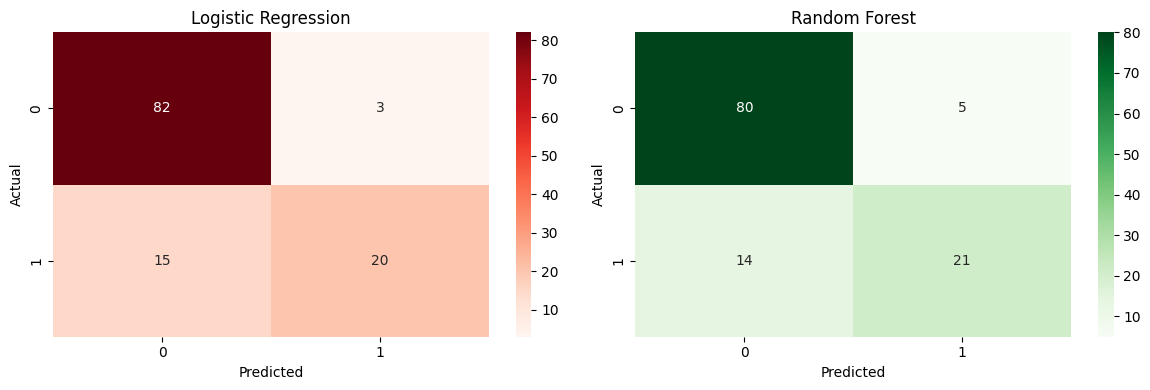

In [95]:
# 1. collecting predictions from trained pipeline
y_pred_lr = reproducible_pipeline.predict(X_test)
y_pred_rf = rf_pipeline.predict(X_test)

# 2. Print evaluation metrics
print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lr))
print('\n')

print("RANDOM FOREST")
print(classification_report(y_test, y_pred_rf))

# 3. Plot Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Logistic Regression
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Reds', ax=axes[0])
axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Random Forest
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

### 4.3 Business Recommendation & Comparison
Looking from the  test results

* **Performance Comparison basis:** compared the overall Accuracy, Precision, Recall, and F1-score of both models to check whiuch model perform better way.
* **Business Point (Cost of errors):** In bank marketing, **Recall** for the positive class (likely subscribers) is usually critical. Missing a likely subscriber (False Negative) means lost revenue, which is often more expensive than sending an offer to a non-subscriber (False Positive).
### **Recommendation**
* **Choose Random Forest:** While both models achieve similar accuracy (~84%), **Random Forest is recommended** because its higher Recall (60% vs. 57%) minimizes missed subscribers (14 vs. 15 False Negatives)—saving the bank from costly lost revenue at the expense of only 2 extra low-cost promotional contacts.


### **5.1 Feature Interpretation & Limitations**

* **3 Positive Sides (Increase Subscription Probability):**
  1. **Previous Contacts:** More past interactions strongly correlate with a higher subscription rate.
  2. **Annual Income Estimate:** Customers with higher estimated incomes are more likely to subscribe.
  3. **Engagement Score:** Highly engaged prospects are more likely to accept the campaign.

* **3 Negative sides (Decrease Subscription Probability):**
  1. **Campaign Contacts:** Excessive outreach contacts during this campaign reduce subscription chance (prospect fatigue).
  2. **Personal Loan:** Customers with outstanding personal loans are highly unlikely to subscribe.
  3. **Housing Loan:** Having a housing loan is also negatively associated with subscription.

* **Key Limitations:**
  * **Correlation = ** Important features show association, not direct cause-and-effect.
  * **Simplification:** Linear relationships assume simple additive effects and miss complex non-linear combinations.
  * **Missing Values:** Handling of missing columns (imputation) can mildly bias feature weights.

In [119]:
# Fetch feature names from preprocessor
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
encoded_cat_features = cat_encoder.get_feature_names_out(categorical_features).tolist()
all_features = numeric_features + encoded_cat_features

# Extract coefficients
coefficients = log_reg.coef_[0]
feature_importance = pd.DataFrame({
    'Feature': all_features,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', key=abs, ascending=False)

print("10 Most Influential Features:")
display(feature_importance.head(10))

10 Most Influential Features:


,Feature,Coefficient
7,job_blue-collar,-0.908043
21,personal_loan_yes,0.905321
20,personal_loan_no,-0.904054
26,contact_month_jul,0.710308
3,previous_contacts,0.707702
22,contact_type_cellular,-0.707254
19,housing_loan_yes,0.667877
18,housing_loan_no,-0.666611
6,job_admin,0.554962
28,contact_month_may,-0.527403


### **5.2 Predictions on 5 Sample Customers**

In [120]:
# Select 5 sample records from the test set
sample_X = X_test.head(5)
sample_y = y_test.head(5)
sample_X_preprocessed = preprocessor.transform(sample_X)

# Predict class and probabilities using Logistic Regression
predicted_classes = log_reg.predict(sample_X_preprocessed)
predicted_probabilities = log_reg.predict_proba(sample_X_preprocessed)[:, 1]

# Display results
samples_df = pd.DataFrame({
    'Actual Subscribed': sample_y.values,
    'Predicted Subscribed': predicted_classes,
    'Subscription Probability (%)': (predicted_probabilities * 100).round(2)
})
display(samples_df)

,Actual Subscribed,Predicted Subscribed,Subscription Probability (%)
0,0,0,22.29
1,1,1,79.92
2,1,0,47.74
3,1,1,62.95
4,0,0,5.58


### **5.3 Business Conclusion**

* **Model Choice:** **Random Forest** is selected over Logistic Regression because its higher recall (60% Vs 57%) helps target more actual subscribers.
* **Evaluation:** The final model achieves **84% overall accuracy**, maintaining an optimal trade-off by missing fewer high-value subscriptions.
* **Next Improvement:** We should adjust the classification probability threshold from `0.5` to `0.35` to prioritize finding more leads and reducing false negatives.